# 05 · Random Forest + comparing every model

The original project's "next steps" said other Kagglers found Random Forest worked best. So we add it, then compare all models on the same test week.

In [1]:
import sys
from pathlib import Path
sys.path.append(str(Path.cwd().parent))   # so we can import src/utils.py

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")

from src.utils import *   # load_data, time_split, make_preprocessor, evaluate, ...

RANDOM_STATE = 42
plt.rcParams["figure.figsize"] = (8, 4.5)

In [2]:
import json
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import average_precision_score, precision_recall_curve

df = load_data()
train, val, test = time_split(df)
X_train, y_train = train[FEATURES], train[TARGET]
X_val, y_val = val[FEATURES], val[TARGET]
X_test, y_test = test[FEATURES], test[TARGET]

## 1. Random Forest

A random forest = many decision trees, each trained on a random sample of rows and features, voting together. Trees don't need scaling (we skip it). `class_weight="balanced_subsample"` handles the imbalance inside each tree.

In [3]:
rows, models = [], {}
for n_trees in [200]:
    for leaf in [1, 3, 10]:
        for depth in [None, 12]:
            rf = Pipeline([("prep", make_preprocessor(scale=False)),
                           ("model", RandomForestClassifier(n_estimators=n_trees, min_samples_leaf=leaf, max_depth=depth,
                                                            class_weight="balanced_subsample", n_jobs=-1,
                                                            random_state=RANDOM_STATE))]).fit(X_train, y_train)
            rows.append({"min_samples_leaf": leaf, "max_depth": depth,
                         "val_pr_auc": average_precision_score(y_val, rf.predict_proba(X_val)[:, 1])})
            models[(leaf, depth)] = rf
rf_table = pd.DataFrame(rows).sort_values("val_pr_auc", ascending=False); rf_table

,min_samples_leaf,max_depth,val_pr_auc
0,1,NaN,0.629763
2,3,NaN,0.620654
4,10,NaN,0.597136
5,10,12.0,0.573287
3,3,12.0,0.527606
1,1,12.0,0.478897


--- Random Forest (final) ---
                accuracy: 0.9968
               precision: 0.4426
   recall (fraud caught): 0.7232
                      f1: 0.5492
     false_negative_rate: 0.2768
           frauds_missed: 31
            false_alarms: 102
                  pr_auc: 0.6829
                 roc_auc: 0.9626
                cost_gbp: 2,859.8600


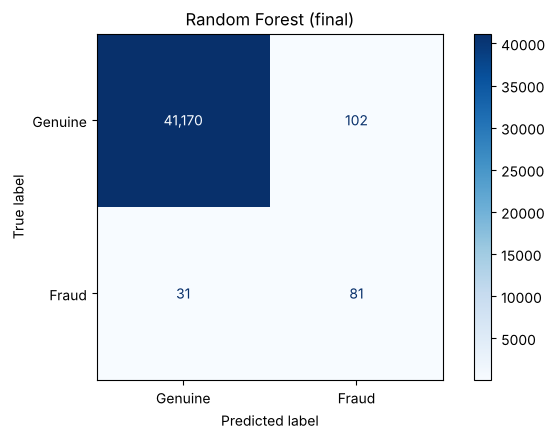

In [4]:
best = rf_table.iloc[0]
final_rf = models[(best["min_samples_leaf"], None if pd.isna(best["max_depth"]) else best["max_depth"])]
p_val = final_rf.predict_proba(X_val)[:, 1]
threshold = best_threshold(y_val, p_val, val["amount_gbp"])
p_test = final_rf.predict_proba(X_test)[:, 1]
rf_results = evaluate("Random Forest (final)", y_test, (p_test >= threshold).astype(int), p_test, test["amount_gbp"])
json.dump({k: (float(v) if not isinstance(v, str) else v) for k, v in rf_results.items()} | {"threshold": threshold},
          open("../results/random_forest.json", "w"), indent=2)

## 2. Which features matter? (permutation importance)

Shuffle one column at a time on the validation set and see how much PR-AUC drops. A big drop = the model relies on that feature. This is more trustworthy than the built-in `feature_importances_`, which favours columns with many distinct values.

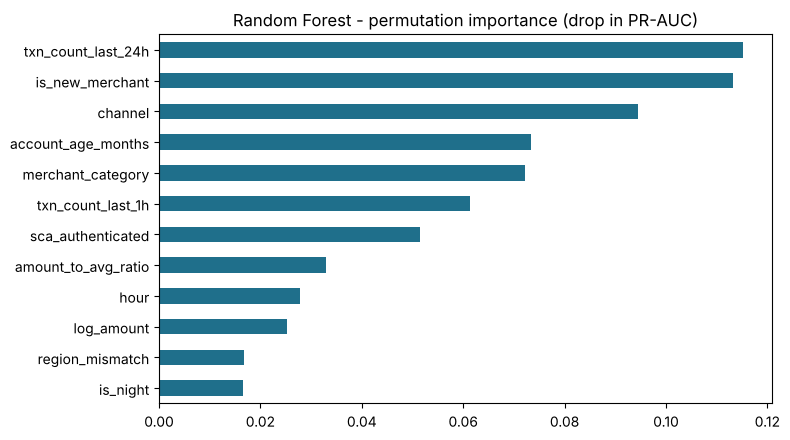

In [5]:
imp = permutation_importance(final_rf, X_val, y_val, scoring="average_precision",
                             n_repeats=5, random_state=RANDOM_STATE, n_jobs=-1)
imp_s = pd.Series(imp.importances_mean, index=FEATURES).sort_values()
imp_s.tail(12).plot.barh(color="#1f6f8b")
plt.title("Random Forest - permutation importance (drop in PR-AUC)"); plt.tight_layout()
plt.savefig("../images/rf_permutation_importance.png", dpi=120, bbox_inches="tight"); plt.show()

## 3. Compare all models (same test week, 26–30 Sep 2026)

In [6]:
names = {"logistic_regression": "Logistic Regression", "kmeans": "K-means (distance)",
         "neural_network": "Neural Network (MLP)", "random_forest": "Random Forest"}
results = pd.DataFrame([json.load(open(f"../results/{f}.json")) | {"model": n} for f, n in names.items()]).set_index("model")
cols = ["recall (fraud caught)", "precision", "f1", "pr_auc", "roc_auc", "frauds_missed", "false_alarms", "cost_gbp", "accuracy"]
results = results[cols]
results.to_csv("../results/model_comparison.csv")
results.round(3)

,recall (fraud caught),precision,f1,pr_auc,roc_auc,frauds_missed,false_alarms,cost_gbp,accuracy
model,,,,,,,,,
Logistic Regression,0.670,0.362,0.470,0.593,0.956,37.0,132.0,3933.72,0.996
K-means (distance),0.473,0.197,0.278,0.182,0.935,59.0,216.0,5038.22,0.993
Neural Network (MLP),0.643,0.353,0.456,0.563,0.959,40.0,132.0,5254.24,0.996
Random Forest,0.723,0.443,0.549,0.683,0.963,31.0,102.0,2859.86,0.997


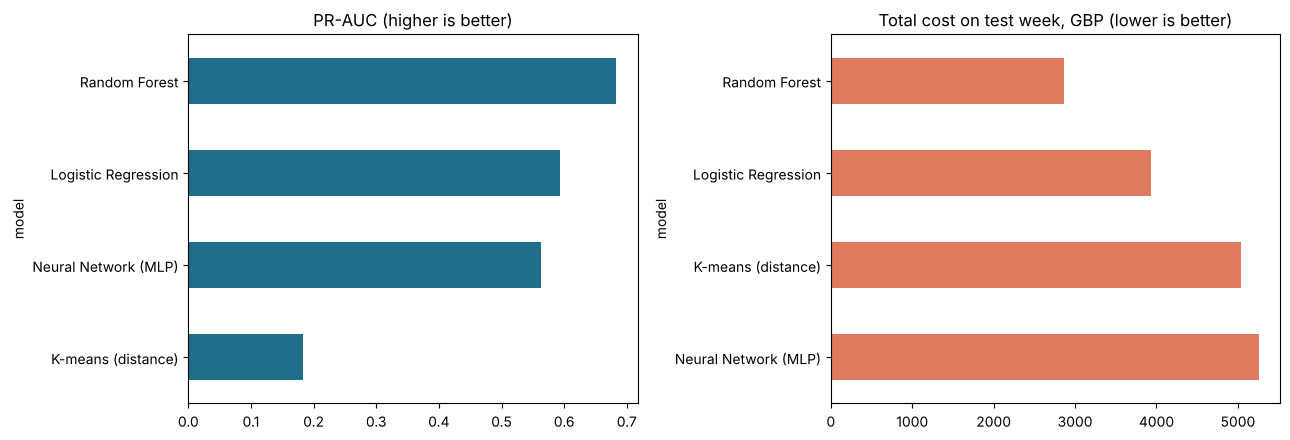

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
results["pr_auc"].sort_values().plot.barh(ax=axes[0], color="#1f6f8b"); axes[0].set_title("PR-AUC (higher is better)")
results["cost_gbp"].sort_values(ascending=False).plot.barh(ax=axes[1], color="#e07a5f")
axes[1].set_title("Total cost on test week, GBP (lower is better)")
plt.tight_layout(); plt.savefig("../images/model_comparison.png", dpi=120, bbox_inches="tight"); plt.show()

### The "no model" cost, for context
If the bank blocked nothing, it would lose the value of every fraud:

In [8]:
no_model_cost = test.loc[test[TARGET] == 1, "amount_gbp"].sum()
print(f"Cost with no fraud model: GBP {no_model_cost:,.2f}")
print(f"Best model cost:          GBP {results['cost_gbp'].min():,.2f} ({results['cost_gbp'].idxmin()})")
print(f"Saving:                   {1 - results['cost_gbp'].min() / no_model_cost:.1%}")

Cost with no fraud model: GBP 14,529.04
Best model cost:          GBP 2,859.86 (Random Forest)
Saving:                   80.3%


## 4. Precision-recall curve

Each point on a curve is a different threshold. Moving right = catching more fraud, but precision usually falls (more false alarms). A curve closer to the top-right is better. The dashed line is a random guess (= the fraud rate).

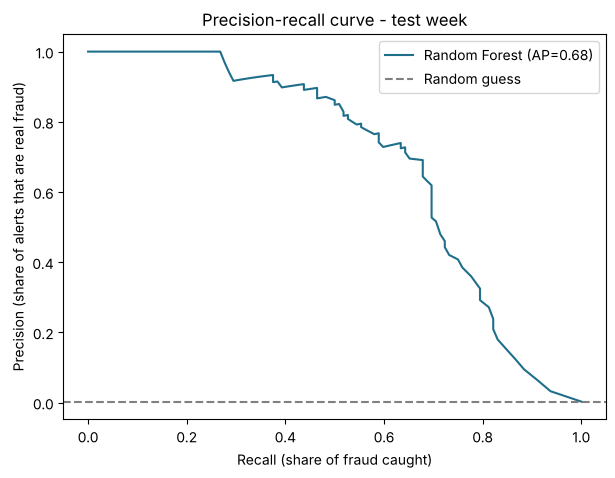

In [9]:
p_test_rf = p_test
plt.figure(figsize=(7, 5))
prec, rec, _ = precision_recall_curve(y_test, p_test_rf)
plt.plot(rec, prec, label=f"Random Forest (AP={average_precision_score(y_test, p_test_rf):.2f})", color="#1f6f8b")
plt.axhline(y_test.mean(), ls="--", c="grey", label="Random guess")
plt.xlabel("Recall (share of fraud caught)"); plt.ylabel("Precision (share of alerts that are real fraud)")
plt.legend(); plt.title("Precision-recall curve - test week")
plt.savefig("../images/pr_curve_rf.png", dpi=120, bbox_inches="tight"); plt.show()

## Conclusions

1. **Accuracy is misleading** — every model (even "do nothing") scores ~99.7%+. Recall, precision, PR-AUC and £ cost tell the real story.
2. **Supervised beats unsupervised**: K-means never sees the labels, so it struggles to separate rare fraud.
3. **Random Forest** is usually the strongest here; **Logistic Regression** is the easiest to explain to a compliance or risk team. In a real UK bank the choice often depends on *explainability* as well as performance.
4. **The threshold is a business decision**, not a modelling default. We chose it to minimise £ cost on the validation week.

### What I'd do next
- Try gradient boosting (XGBoost / LightGBM)
- Real velocity features built from the transaction history (per-customer rolling windows)
- Probability calibration, and monitoring for drift as fraud patterns change
- Test on real or public data (e.g. the Kaggle European credit card dataset) to check the method generalises